# Ames Housing Data Set

**Team:** The Outliers
**Students:** Cor'layshia Cooper, Joe Cai Yuan, Jonathan Watson, Morgan Williams


---


In [8]:
import pandas as pd
import numpy as np

The following code reads the data from test and train. It creates a copy of the information so that the original set does not get altered.

In [9]:

train = pd.read_csv("train.csv")                
test = pd.read_csv("test.csv")

df = train.copy()                                  
test_df = test.copy()       

The following code prints the shape of both the training and testing dataset. It prints the first 5 rows, with the column information, summary and does a check for duplicates.

In [10]:
print("\n--- Dataset Overview ---")
print("Training Dataset Shape:", df.shape)
print("Testing Dataset Shape:", test_df.shape)

print("\n--- First 5 Rows ---")
print(df.head())

print("\n--- Column Information ---")
df.info()

print("\n--- Statistical Summary ---")
print(df.describe())

print("\n--- Duplicate Check ---")
print("Duplicate Rows:", df.duplicated().sum())
print("Duplicate IDs:", df["Id"].duplicated().sum())



--- Dataset Overview ---
Training Dataset Shape: (1460, 81)
Testing Dataset Shape: (1459, 80)

--- First 5 Rows ---
   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...     

The following code checks for missing values and gives an average of the missing values from that value.

In [11]:
print("\n--- Missing Value Report ---")

missing_values = df.isnull().sum()

missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_report = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage
})

missing_report = missing_report[missing_report["Missing Values"] > 0]

missing_report = missing_report.sort_values(
    by="Missing Percentage",
    ascending=False
)

print(missing_report)


--- Missing Value Report ---
              Missing Values  Missing Percentage
PoolQC                  1453           99.520548
MiscFeature             1406           96.301370
Alley                   1369           93.767123
Fence                   1179           80.753425
MasVnrType               872           59.726027
FireplaceQu              690           47.260274
LotFrontage              259           17.739726
GarageType                81            5.547945
GarageYrBlt               81            5.547945
GarageFinish              81            5.547945
GarageQual                81            5.547945
GarageCond                81            5.547945
BsmtFinType2              38            2.602740
BsmtExposure              38            2.602740
BsmtFinType1              37            2.534247
BsmtCond                  37            2.534247
BsmtQual                  37            2.534247
MasVnrArea                 8            0.547945
Electrical                 1           

The following code prints out the names of each column, as well as how many columns are numerical and categorical.

In [12]:
print("\n--- Column Classification ---")

numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_columns = df.select_dtypes(
    include=["object"]
).columns

print("Numerical Columns:")
print(list(numerical_columns))

print("\nCategorical Columns:")
print(list(categorical_columns))

print("\nNumber of Numerical Columns:", len(numerical_columns))
print("Number of Categorical Columns:", len(categorical_columns))



--- Column Classification ---
Numerical Columns:
['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice']

Categorical Columns:
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'Kitche

/var/folders/nx/_1890zc549scghccgx8xtxcm0000gn/T/ipykernel_67312/977081977.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


The following code prints out the sales price check and the summary of the Sales Price colunm.

In [13]:
print("\n--- Sale Price Check ---")                               

print("Missing Sale Prices:", df["SalePrice"].isnull().sum())
print("\nSale Price Summary:")
print(df["SalePrice"].describe())


--- Sale Price Check ---
Missing Sale Prices: 0

Sale Price Summary:
count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


The following code prints out a column check for the train and test datasets.

In [14]:

print("\n--- Train and Test Column Check ---")

train_columns = set(df.columns)
test_columns = set(test_df.columns)

print("Columns only in training data:")
print(train_columns - test_columns)

print("\nColumns only in testing data:")
print(test_columns - train_columns)

print("\nInitial inspection complete.")



--- Train and Test Column Check ---
Columns only in training data:
{'SalePrice'}

Columns only in testing data:
set()

Initial inspection complete.


# Part 2: Data Cleaning and Preparation

After inspecting the raw data, we now will clean it. Before touching any missing values, two things are important to note. First, most of the "missing" values in this data set are not truly missing. The `data_description.txt` file says `NA` values in columns like `PoolQC`, `Alley`, and `GarageType` means the house does not have that feature. Dropping these would be wrong. Second, **pandas automatically converts the `None` object into a null value. `MasVnrType` has a real `None` value (no masonry veneer), so the 59.7% "missing" in the data report is misleading.

We will work on a copy of the DataFrame called `clean` so that the raw `df` stays untouched.

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
clean = df.copy()

## 2.1: Check if missing values are truly absent features.

We will now compare a column's missing count with how many of those rows have a zero in a related numeric column. If the counts are equal, then the "missing values" are not truly missing. `Alley` and `Fence` have no numeric column to compare with, so they cannot be tested this way. The `data_description.txt` file defines `NA` as "No alley access" and "No fence".

In [17]:
checks = {
    "PoolQC":       "PoolArea",
    "FireplaceQu":  "Fireplaces",
    "GarageType":   "GarageArea",
    "GarageFinish": "GarageArea",
    "GarageQual":   "GarageArea",
    "GarageCond":   "GarageArea",
    "BsmtQual":     "TotalBsmtSF",
    "BsmtCond":     "TotalBsmtSF",
    "BsmtExposure": "TotalBsmtSF",
    "BsmtFinType1": "TotalBsmtSF",
    "BsmtFinType2": "TotalBsmtSF",
    "MiscFeature":  "MiscVal",
    "Alley":        None,
    "Fence":        None,
}
rows = []
for col, indicator in checks.items():
    n_missing = clean[col].isna().sum()
    if indicator is None:
        rows.append({"Column": col, "Related column": "(none)", "Missing": n_missing,
                     "Missing AND related = 0": "n/a", "Unexplained": "n/a"})
    else:
        n_zero = (clean[col].isna() & (clean[indicator] == 0)).sum()
        rows.append({"Column": col, "Related column": indicator, "Missing": n_missing,
                     "Missing AND related = 0": n_zero, "Unexplained": n_missing - n_zero})
pd.DataFrame(rows)

,Column,Related column,Missing,Missing AND related = 0,Unexplained
0,PoolQC,PoolArea,1453,1453,0
1,FireplaceQu,Fireplaces,690,690,0
2,GarageType,GarageArea,81,81,0
3,GarageFinish,GarageArea,81,81,0
4,GarageQual,GarageArea,81,81,0
5,GarageCond,GarageArea,81,81,0
6,BsmtQual,TotalBsmtSF,37,37,0
7,BsmtCond,TotalBsmtSF,37,37,0
8,BsmtExposure,TotalBsmtSF,38,37,1
9,BsmtFinType1,TotalBsmtSF,37,37,0


For all testable columns but two have equivalent counts. Both `BsmtExposure` and `BsmtFinType2` have 1 unexplained missing value. Those are truly missing values.

## 2.2: Recode "feature absent" values

Now that we know which column's have values that are actually missing, we will replace the misleading "missing" values with the value `"None"`.

A house has no basement if `TotalBsmtSF == 0`. For the two missing values, both houses have basements, but they are missing a value related to it. Therefore, we will fill the two missing values with the most common value.

In [18]:
# Columns where NaN means "this feature is absent"
absent_cols = ["PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
               "GarageType", "GarageFinish", "GarageQual", "GarageCond"]
clean[absent_cols] = clean[absent_cols].fillna("None")

# Basement: absent only when TotalBsmtSF == 0
bsmt_cols = ["BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"]
no_bsmt = clean["TotalBsmtSF"] == 0
for col in bsmt_cols:
    clean.loc[no_bsmt, col] = clean.loc[no_bsmt, col].fillna("None")
    # any leftover NaN is a real gap in a house that has a basement
    clean[col] = clean[col].fillna(clean[col].mode()[0])

# Masonry veneer: pandas read the real category "None" as NaN.
# If the area is known, the veneer type was "None". If both are NaN, it is truly missing.
truly_missing_vnr = clean["MasVnrArea"].isna()
clean.loc[clean["MasVnrType"].isna() & ~truly_missing_vnr, "MasVnrType"] = "None"
print("MasVnr rows that are truly missing:", truly_missing_vnr.sum())

MasVnr rows that are truly missing: 8


The masonry veneer data has eight missing rows. Additionally, seven rows have contradictary data. Five are labeled `None` with a nonzero area and two with a veneer type but an area of 0. We decided not to change these inconsistent rows because they are few (0.5%) and we cannot know which value is wrong.

## 2.3: Handle the values that are truly missing

Now that we know only a few columns have real gaps, we must now decide how to approach the incomplete data.

| Column | Missing | Approach | Why |
|---|---|---|---|
| `LotFrontage` | 259 (17.7%) | Fill with the **neighborhood median**, and add a flag column | Lot frontage tends to be similar within a neighborhood. The flag lets us check later whether imputed rows behave differently. |
| `MasVnrType` / `MasVnrArea` | 8 | Set to `"None"` / `0` | The most common case, and it affects 0.5% of rows. |
| `Electrical` | 1 | Fill with the most common value | One row, negligible effect. |
| `GarageYrBlt` | 81 | **Leave as NaN** | These houses have no garage. A year of 0 would be meaningless and would distort averages. We use a `HasGarage` flag instead. |

In [19]:
# LotFrontage: flag first, then impute by neighborhood median
clean["LotFrontage_missing"] = clean["LotFrontage"].isna().astype(int)
clean["LotFrontage"] = clean.groupby("Neighborhood")["LotFrontage"].transform(
    lambda s: s.fillna(s.median())
)
clean["LotFrontage"] = clean["LotFrontage"].fillna(clean["LotFrontage"].median())  # safety net

# The 8 truly missing masonry rows
clean.loc[truly_missing_vnr, "MasVnrType"] = "None"
clean.loc[truly_missing_vnr, "MasVnrArea"] = 0

# Electrical: one row
clean["Electrical"] = clean["Electrical"].fillna(clean["Electrical"].mode()[0])

# MSSubClass is a building-type CODE (20, 60, 190...), not a quantity, so treat it as a category
clean["MSSubClass"] = clean["MSSubClass"].astype(str)

remaining = clean.isna().sum()
print("Remaining missing values after cleaning:")
print(remaining[remaining > 0])

Remaining missing values after cleaning:
GarageYrBlt    81
dtype: int64


Now we have one column with missing values, which was intentionally left alone. Before, nineteen columns had missing values.

## 2.4: Investigate outliers

The outliers that jump out the most are houses with extremely large living areas (`GrLivArea` greater than 4,000 sq ft), so we will investigate them.

In [20]:
big = clean[clean["GrLivArea"] > 4000]
big[["Id", "GrLivArea", "SalePrice", "OverallQual", "Neighborhood", "SaleCondition"]]

,Id,GrLivArea,SalePrice,OverallQual,Neighborhood,SaleCondition
523,524,4676,184750,10,Edwards,Partial
691,692,4316,755000,10,NoRidge,Normal
1182,1183,4476,745000,10,NoRidge,Abnorml
1298,1299,5642,160000,10,Edwards,Partial


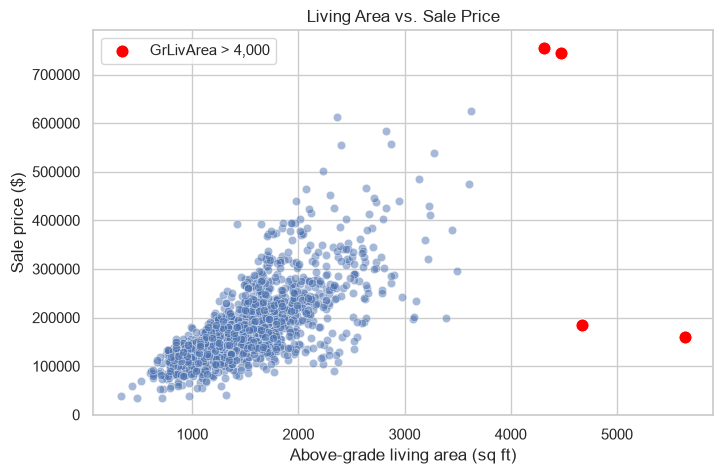

In [21]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=clean, x="GrLivArea", y="SalePrice", alpha=0.5, ax=ax)
sns.scatterplot(data=big, x="GrLivArea", y="SalePrice", color="red", s=90, ax=ax,
                label="GrLivArea > 4,000")
ax.set_title("Living Area vs. Sale Price")
ax.set_xlabel("Above-grade living area (sq ft)")
ax.set_ylabel("Sale price ($)")
plt.show()

We can see that two of the four extremely large houses sold for far less than their size suggests. Both have `SaleCondition = Partial`, which means the home was not completed when it was last assessed, so their low prices likely refelct a price for the incomplete house. The other two sold for prices that are reasonable for their size and quality ratings.

We decided to not delete anything, and instead add a flag column and check how much these rows affect our results. We can then later choose whether we want to exclude the two `Partial` rows.

In [22]:
clean["Outlier_LargePartial"] = ((clean["GrLivArea"] > 4000) &
                                 (clean["SaleCondition"] == "Partial")).astype(int)

r_all  = clean["GrLivArea"].corr(clean["SalePrice"])
r_drop = clean.loc[clean["Outlier_LargePartial"] == 0, "GrLivArea"].corr(
         clean.loc[clean["Outlier_LargePartial"] == 0, "SalePrice"])
print(f"Correlation GrLivArea vs SalePrice, all rows:           {r_all:.3f}")
print(f"Correlation GrLivArea vs SalePrice, without 2 outliers: {r_drop:.3f}")

Correlation GrLivArea vs SalePrice, all rows:           0.709
Correlation GrLivArea vs SalePrice, without 2 outliers: 0.735


Removing the two rows raises the correlation from roughly 0.71 to 0.74. That is a slight, but real shift. For now, we keep them in `clean`, but we now have flagged them.

## Part 3: Feature Engineeering

These new columns will be built using existing columns for easier interpretation. The original columns will all be kept.

In [23]:
# Size
clean["TotalSF"] = clean["TotalBsmtSF"] + clean["1stFlrSF"] + clean["2ndFlrSF"]

# Age
clean["HouseAge"] = clean["YrSold"] - clean["YearBuilt"]
clean["YearsSinceRemodel"] = clean["YrSold"] - clean["YearRemodAdd"]
clean["Remodeled"] = (clean["YearRemodAdd"] != clean["YearBuilt"]).astype(int)

# Bathrooms (a half bath counts as 0.5)
clean["TotalBaths"] = (clean["FullBath"] + 0.5 * clean["HalfBath"] +
                       clean["BsmtFullBath"] + 0.5 * clean["BsmtHalfBath"])

# Yes/No features
clean["HasGarage"]    = (clean["GarageArea"] > 0).astype(int)
clean["HasBasement"]  = (clean["TotalBsmtSF"] > 0).astype(int)
clean["HasFireplace"] = (clean["Fireplaces"] > 0).astype(int)
clean["HasPool"]      = (clean["PoolArea"] > 0).astype(int)

new_features = ["TotalSF", "HouseAge", "YearsSinceRemodel", "Remodeled", "TotalBaths",
                "HasGarage", "HasBasement", "HasFireplace", "HasPool"]
clean[new_features].describe().T[["count", "mean", "min", "max"]]

,count,mean,min,max
TotalSF,1460.0,2567.048630,334.0,11752.0
HouseAge,1460.0,36.547945,0.0,136.0
YearsSinceRemodel,1460.0,22.950000,-1.0,60.0
Remodeled,1460.0,0.476712,0.0,1.0
TotalBaths,1460.0,2.210616,1.0,6.0
HasGarage,1460.0,0.944521,0.0,1.0
HasBasement,1460.0,0.974658,0.0,1.0
HasFireplace,1460.0,0.527397,0.0,1.0
HasPool,1460.0,0.004795,0.0,1.0


We will now test the new columns for impossible values or inconsistency with the cleaned data. A "REVIEW" result means something needs a look.

In [24]:
results = []
def add(feature, check, ok, detail):
    results.append({"Feature": feature, "Check": check,
                    "Result": "PASS" if ok else "REVIEW", "Detail": detail})

# Size
add("TotalSF", "all values are positive", (clean["TotalSF"] > 0).all(),
    f"range {clean['TotalSF'].min():,} to {clean['TotalSF'].max():,} sq ft")
add("TotalSF", "equals basement + 1st floor + 2nd floor",
    (clean["TotalSF"] == clean["TotalBsmtSF"] + clean["1stFlrSF"] + clean["2ndFlrSF"]).all(), "")

# Age
add("HouseAge", "no negative values (sold before built)", (clean["HouseAge"] >= 0).all(),
    f"range {clean['HouseAge'].min()} to {clean['HouseAge'].max()}; "
    f"{(clean['HouseAge'] == 0).sum()} houses sold in their build year")
n_neg = (clean["YearsSinceRemodel"] < 0).sum()
add("YearsSinceRemodel", "no negative values (sold before remodel)", n_neg == 0,
    f"{n_neg} negative (see below)")
add("Remodeled", "no remodel year earlier than build year",
    (clean["YearRemodAdd"] >= clean["YearBuilt"]).all(),
    f"{clean['Remodeled'].sum()} remodeled, {(clean['Remodeled'] == 0).sum()} not")

# Bathrooms
add("TotalBaths", "at least 1, and only whole or half values",
    ((clean["TotalBaths"] >= 1) & ((clean["TotalBaths"] * 2) % 1 == 0)).all(),
    f"range {clean['TotalBaths'].min()} to {clean['TotalBaths'].max()}")

# Yes/No flags: must agree with the cleaned quality/type column
for flag, col in [("HasGarage", "GarageType"), ("HasBasement", "BsmtQual"),
                  ("HasFireplace", "FireplaceQu"), ("HasPool", "PoolQC")]:
    mismatches = ((clean[flag] == 0) != (clean[col] == "None")).sum()
    add(flag, f"agrees with {col} == 'None'", mismatches == 0,
        f"{mismatches} mismatches; {clean[flag].sum()} houses have the feature")

pd.DataFrame(results)

,Feature,Check,Result,Detail
0,TotalSF,all values are positive,PASS,"range 334 to 11,752 sq ft"
1,TotalSF,equals basement + 1st floor + 2nd floor,PASS,
2,HouseAge,no negative values (sold before built),PASS,range 0 to 136; 64 houses sold in their build ...
3,YearsSinceRemodel,no negative values (sold before remodel),REVIEW,1 negative (see below)
4,Remodeled,no remodel year earlier than build year,PASS,"696 remodeled, 764 not"
5,TotalBaths,"at least 1, and only whole or half values",PASS,range 1.0 to 6.0
6,HasGarage,agrees with GarageType == 'None',PASS,0 mismatches; 1379 houses have the feature
7,HasBasement,agrees with BsmtQual == 'None',PASS,0 mismatches; 1423 houses have the feature
8,HasFireplace,agrees with FireplaceQu == 'None',PASS,0 mismatches; 770 houses have the feature
9,HasPool,agrees with PoolQC == 'None',PASS,0 mismatches; 7 houses have the feature


In [25]:
clean.loc[clean["YearsSinceRemodel"] < 0, ["Id", "YearBuilt", "YearRemodAdd", "YrSold", "SaleCondition"]]

,Id,YearBuilt,YearRemodAdd,YrSold,SaleCondition
523,524,2007,2008,2007,Partial


One house (Id 524) has a remodel year one year later than its sale year. It has `Partial` sale condition, so the remodel date probably reflects its completion. We will leave it as is and take note of it. The rest of the columns pass their checks.

**Two notes for interpretation:**
1. `TotalSF` is basement + first floor + second floor. It differs from `GrLivArea + TotalBsmtSF` in houses with `LowQualFinSF` greater than zero, because `GrLivArea` includes unfinished area and `TotalSF` does not.
2. Only seven houses have a pool, so `HasPool` will not tell us much on its own.

## Part 4: EDA

To answer what makes a house sell for a higher price, we will investigate which characteristics are associated with sale prices. Specifically, we will be looking into: House size, overall quality, number of bathrooms and bedrooms, age of the house, garage and basements availability, neighborhood, and renovations.

We will start by creating a histogram to understand the distribution of house prices.

## 4.1 Histogram and Boxplot 


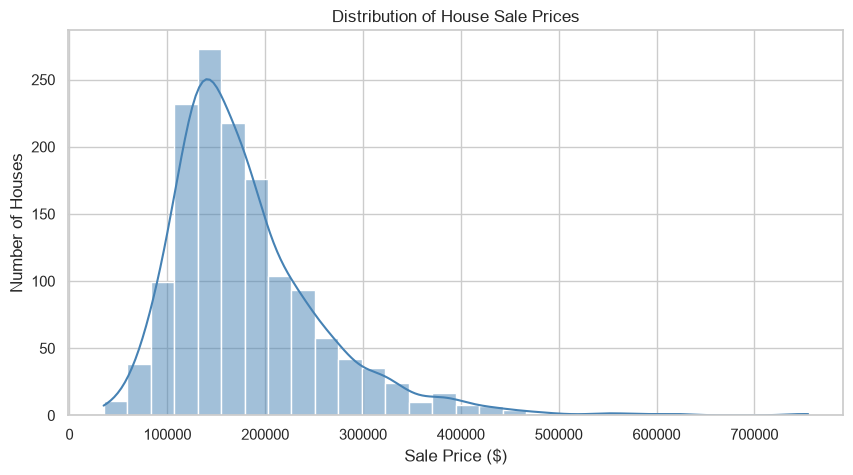

In [26]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=clean,
    x="SalePrice",
    bins=30,
    kde=True,
    color="steelblue"
)

plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price ($)")
plt.ylabel("Number of Houses")

plt.show()

Next, we will create a boxplot to identify the spread of prices and potentially identify unusual observations

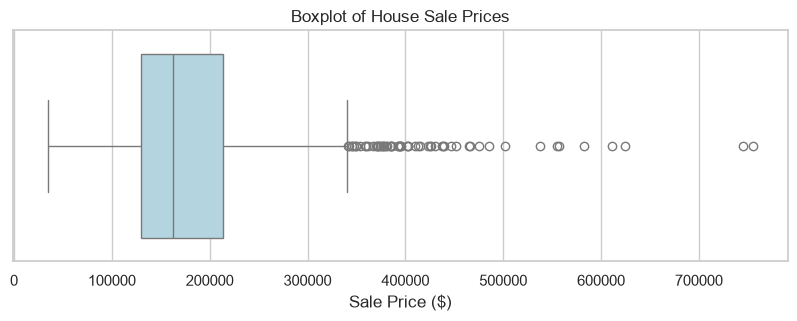

In [27]:
plt.figure(figsize=(10, 3))

sns.boxplot(
    data=clean,
    x="SalePrice",
    color="lightblue"
)

plt.title("Boxplot of House Sale Prices")
plt.xlabel("Sale Price ($)")

plt.show()

To investigate the boxplot, we will calculate the statistical boundaries used by the boxplot, this tells us how many houses fall outside of it.

In [28]:
Q1 = clean["SalePrice"].quantile(0.25)
Q3 = clean["SalePrice"].quantile(0.75)

IQR = Q3 - Q1

upper_limit = Q3 + 1.5 * IQR
lower_limit = Q1 - 1.5 * IQR

outliers = clean[
    (clean["SalePrice"] < lower_limit) |
    (clean["SalePrice"] > upper_limit)
]

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Number of potential outliers:", len(outliers))

Lower limit: 3937.5
Upper limit: 340037.5
Number of potential outliers: 61


The limits of the boxplot are 3,937.50 and 340,037.50. Since the cheapest house sold was for 34,900 dollars, there are no lower outliers. Additionally, out of all the houses, we have 61 that were sold above the upper limit, so around 4.18%. We will keep these outliers because it is in our interest to find what made these houses were sold above the average price in comparison to other houses.

### 4.2 Numerical Variables and Their Relationship with SalePrice

In [29]:
# Select numerical features to investigate
numerical_features = [
    "TotalSF",
    "GrLivArea",
    "OverallQual",
    "HouseAge",
    "TotalBaths",
    "GarageArea"
]

# Calculate correlations with SalePrice
correlations = clean[numerical_features + ["SalePrice"]].corr()

# Display correlations with SalePrice
saleprice_corr = correlations["SalePrice"].drop("SalePrice")

saleprice_corr = saleprice_corr.sort_values(
    ascending=False
)

print("--- Correlation with SalePrice ---")
print(saleprice_corr)

--- Correlation with SalePrice ---
OverallQual    0.790982
TotalSF        0.782260
GrLivArea      0.708624
TotalBaths     0.631731
GarageArea     0.623431
HouseAge      -0.523350
Name: SalePrice, dtype: float64


The previous code helps calculate the correlation of each variable to the sale price. This helps to give us an idea of which characteristics have the strongest relationships with house prices. The strongest relationships are the overall quality, total square fottage and above-ground living area.

#### Relationship Between Total Square Footage and Sale Price

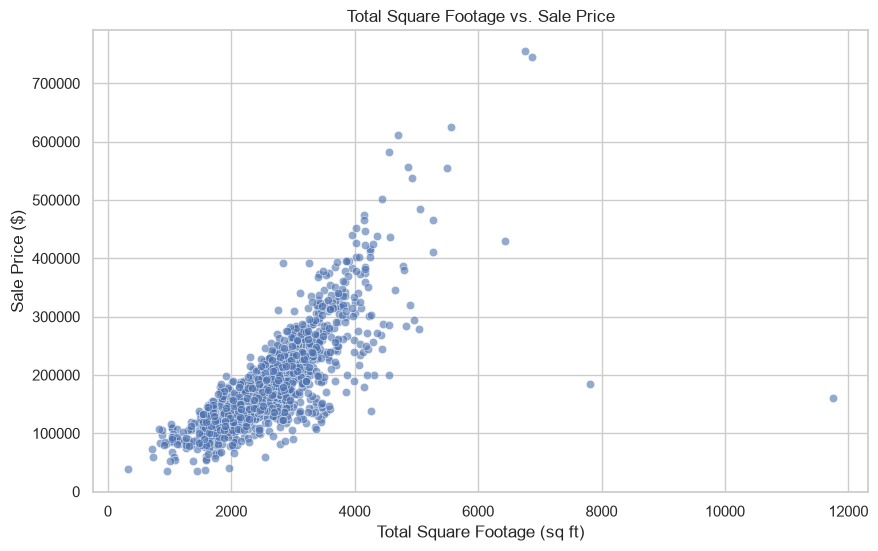

In [30]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=clean,
    x="TotalSF",
    y="SalePrice",
    alpha=0.6
)

plt.title("Total Square Footage vs. Sale Price")
plt.xlabel("Total Square Footage (sq ft)")
plt.ylabel("Sale Price ($)")

plt.show()

We will investigate the 2 outliers with the next code:

In [31]:
unusual_houses = clean[
    clean["TotalSF"] > 7000
]

unusual_houses[
    ["Id", "TotalSF", "GrLivArea", "TotalBsmtSF",
     "SalePrice", "OverallQual", "Neighborhood",
     "SaleCondition"]
].sort_values("TotalSF", ascending=False)

,Id,TotalSF,GrLivArea,TotalBsmtSF,SalePrice,OverallQual,Neighborhood,SaleCondition
1298,1299,11752,5642,6110,160000,10,Edwards,Partial
523,524,7814,4676,3138,184750,10,Edwards,Partial


The scatterplot shows a strong positive relationship between total square footage and sale price, supported by a correlation of 0.782.

However, two unusually large houses do not follow the general pattern. House IDs 1299 and 524 have total areas of 11,752 sq ft and 7,814 sq ft, but sold for only $160,000 and $184,750, respectively.

Both properties have an OverallQual rating of 10, are located in Edwards, and have a SaleCondition of Partial. This suggests that their incomplete sale status may help explain their unusually low prices relative to their size.

We decided to retain both observations because we cannot establish that their recorded prices are incorrect. Their presence is important to consider when interpreting the relationship between house size and sale price.



#### Above-ground Living Area vs. Sale Price

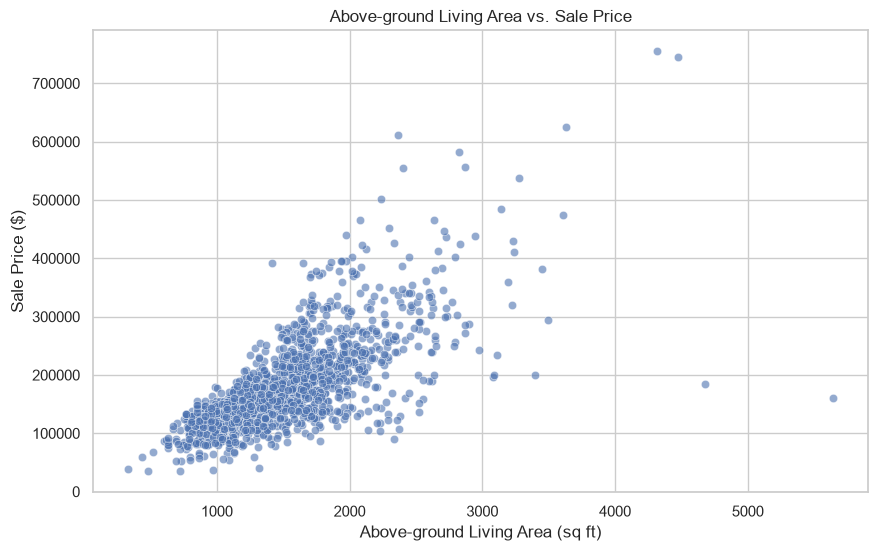

In [32]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=clean,
    x="GrLivArea",
    y="SalePrice",
    alpha=0.6
)

plt.title("Above-ground Living Area vs. Sale Price")
plt.xlabel("Above-ground Living Area (sq ft)")
plt.ylabel("Sale Price ($)")

plt.show()

Interpretation: Above-ground Living Area vs. Sale Price

The scatterplot shows a positive relationship between above-ground living area and sale price. Generally, houses with larger living areas tend to sell for higher prices.

The correlation coefficient of 0.709 indicates a strong positive linear relationship. However, this is slightly weaker than the correlation observed for TotalSF (0.782).

Two unusually large houses stand out from the general pattern. These are the same properties identified in our previous analysis (IDs 1299 and 524). Both have a SaleCondition of Partial, which may help explain their relatively low sale prices.

Overall, above-ground living area is an important characteristic associated with sale price, although other factors also contribute to differences in house prices.

#### Overall Quality vs. Sale Price

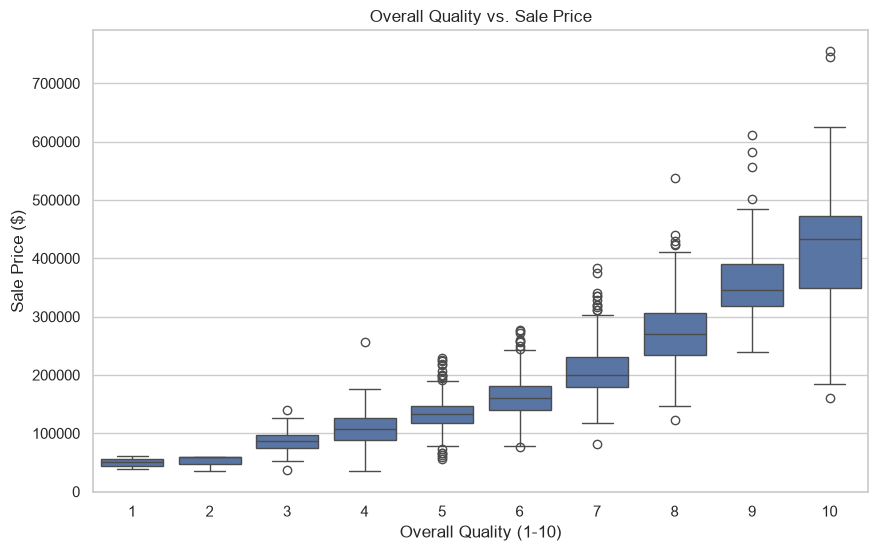

In [33]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=clean,
    x="OverallQual",
    y="SalePrice"
)

plt.title("Overall Quality vs. Sale Price")
plt.xlabel("Overall Quality (1-10)")
plt.ylabel("Sale Price ($)")

plt.show()

In [34]:
quality_summary = clean.groupby("OverallQual")["SalePrice"].agg(
    ["count", "mean", "median", "min", "max"]
)

print(quality_summary.round(2))

             count       mean    median     min     max
OverallQual                                            
1                2   50150.00   50150.0   39300   61000
2                3   51770.33   60000.0   35311   60000
3               20   87473.75   86250.0   37900  139600
4              116  108420.66  108000.0   34900  256000
5              397  133523.35  133000.0   55993  228950
6              374  161603.03  160000.0   76000  277000
7              319  207716.42  200141.0   82500  383970
8              168  274735.54  269750.0  122000  538000
9               43  367513.02  345000.0  239000  611657
10              18  438588.39  432390.0  160000  755000


We have a pretty noticeable upward pattern of the mean price as the overall quality goes up. We should be careful with ratings 1 and 2 because we only have 2 and 3 houses respectively that fall under those ratings, so those sample sizes are too small to make reliable comparisons.

In the next code, we will investigate the outliers.

In [37]:
outlier_results = []

for quality in sorted(clean["OverallQual"].unique()):

    group = clean[clean["OverallQual"] == quality]

    Q1 = group["SalePrice"].quantile(0.25)
    Q3 = group["SalePrice"].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = group[
        (group["SalePrice"] < lower_limit) |
        (group["SalePrice"] > upper_limit)
    ]

    outlier_results.append({
        "OverallQual": quality,
        "House Count": len(group),
        "Outlier Count": len(outliers),
        "Lower Limit": lower_limit,
        "Upper Limit": upper_limit
    })

outlier_summary = pd.DataFrame(outlier_results)

print(outlier_summary.round(2).to_string(index=False))

 OverallQual  House Count  Outlier Count  Lower Limit  Upper Limit
           1            2              0     28450.00     71850.00
           2            3              0     29138.75     78516.75
           3           20              2     42500.00    130500.00
           4          116              1     31750.00    181750.00
           5          397             17     74500.00    190500.00
           6          374              9     76312.50    243812.50
           7          319             12    102550.00    307670.00
           8          168              6    127018.75    413788.75
           9           43              4    212877.25    495819.25
          10           18              3    164125.00    658125.00


In [38]:
# Identify potential outliers separately within each quality rating

outlier_houses = []

for quality in sorted(clean["OverallQual"].unique()):

    group = clean[clean["OverallQual"] == quality]

    Q1 = group["SalePrice"].quantile(0.25)
    Q3 = group["SalePrice"].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = group[
        (group["SalePrice"] < lower_limit) |
        (group["SalePrice"] > upper_limit)
    ]

    outlier_houses.append(outliers)

outlier_houses = pd.concat(outlier_houses)

# Display important information about the unusual houses

outlier_houses[
    ["Id", "OverallQual", "SalePrice", "TotalSF",
     "GrLivArea", "Neighborhood", "SaleCondition"]
].sort_values("SalePrice", ascending=False)

,Id,OverallQual,SalePrice,TotalSF,GrLivArea,Neighborhood,SaleCondition
691,692,10,755000,6760,4316,NoRidge,Normal
1182,1183,10,745000,6872,4476,NoRidge,Abnorml
898,899,9,611657,4694,2364,NridgHt,Partial
803,804,9,582933,4556,2822,NridgHt,Partial
1046,1047,9,556581,4860,2868,StoneBr,Partial
769,770,8,538000,4929,3279,StoneBr,Normal
178,179,9,501837,4450,2234,StoneBr,Partial
473,474,8,440000,3952,1976,NridgHt,Partial
496,497,8,430000,6428,3228,NoRidge,Normal
1142,1143,8,424870,4294,2828,CollgCr,Partial


The outlier analysis shows that some houses have unusually high or low selling prices compared with other houses of similar overall quality. However, these values are not necessarily errors. Some high-priced outliers may reflect larger homes or desirable features, while unusually low-priced outliers may be influenced by sale conditions. Therefore, we decided to retain these observations rather than automatically remove them.

## Categorical Feature Analysis

#### Neighborhood vs SalePrice

We will find out the average and median slling price of each neighborhood

In [39]:

neighborhood_prices = clean.groupby("Neighborhood")["SalePrice"].agg(
    ["count", "mean", "median"]
).sort_values(by="mean", ascending=False)

neighborhood_prices.columns = [
    "House Count",
    "Average SalePrice",
    "Median SalePrice"
]

print(neighborhood_prices.round(2))


              House Count  Average SalePrice  Median SalePrice
Neighborhood                                                  
NoRidge                41          335295.32          301500.0
NridgHt                77          316270.62          315000.0
StoneBr                25          310499.00          278000.0
Timber                 38          242247.45          228475.0
Veenker                11          238772.73          218000.0
Somerst                86          225379.84          225500.0
ClearCr                28          212565.43          200250.0
Crawfor                51          210624.73          200624.0
CollgCr               150          197965.77          197200.0
Blmngtn                17          194870.88          191000.0
Gilbert                79          192854.51          181000.0
NWAmes                 73          189050.07          182900.0
SawyerW                59          186555.80          179900.0
Mitchel                49          156270.12          1

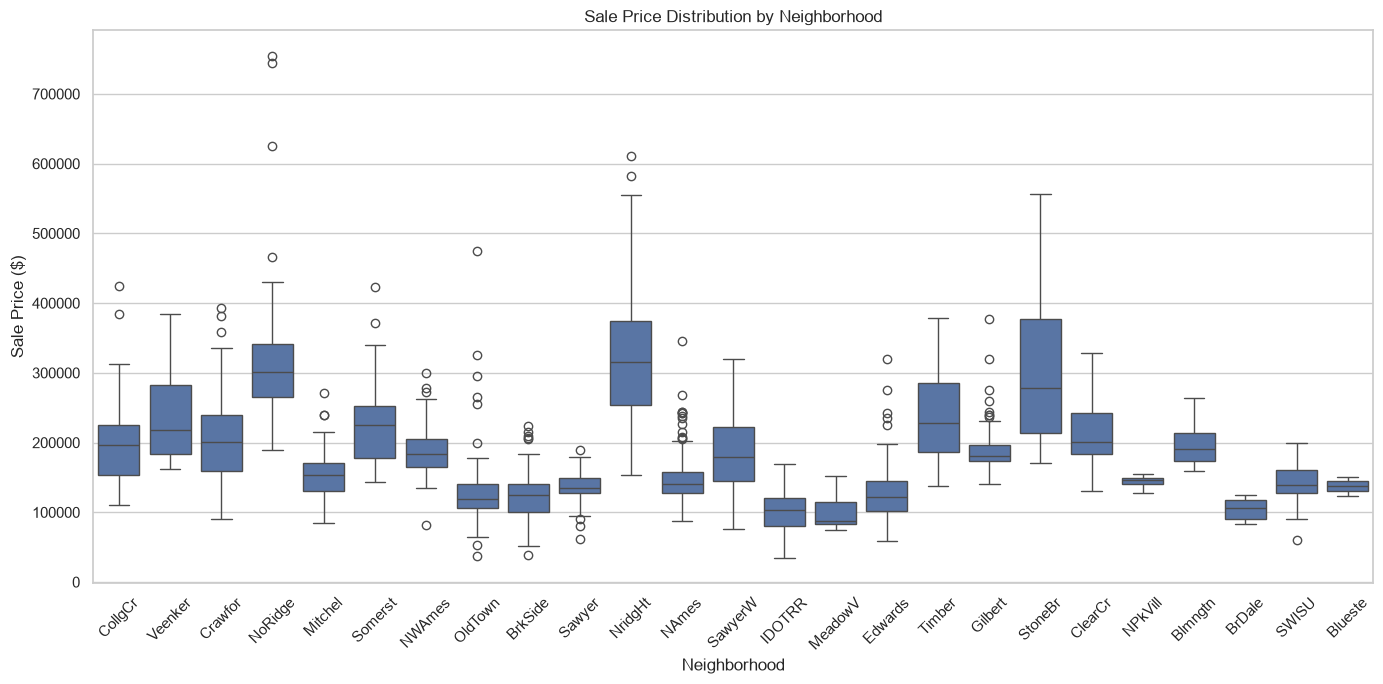

In [40]:

plt.figure(figsize=(14, 7))

sns.boxplot(
    data=clean,
    x="Neighborhood",
    y="SalePrice"
)

plt.title("Sale Price Distribution by Neighborhood")
plt.xlabel("Neighborhood")
plt.ylabel("Sale Price ($)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


The analysis shows noticeable differences in selling prices across neighborhoods. NridgHt has the highest median selling price at $315,000, while MeadowV has the lowest at $88,000. NoRidge has the highest average selling price at approximately $335,295. The boxplot also shows that many neighborhoods contain potential outliers, suggesting considerable variation in selling prices within individual neighborhoods. Overall, these results suggest that neighborhood is an important factor associated with house sale prices.

In the next code, we will investigate whether kitchen quality is associated with higher selling prices.

#### Kitchen Quality vs Selling price


In [41]:
kitchen_prices = clean.groupby("KitchenQual")["SalePrice"].agg(
    ["count", "mean", "median"]
)

kitchen_prices.columns = [
    "House Count",
    "Average SalePrice",
    "Median SalePrice"
]

print(kitchen_prices.round(2))


             House Count  Average SalePrice  Median SalePrice
KitchenQual                                                  
Ex                   100          328554.67          316750.0
Fa                    39          105565.21          115000.0
Gd                   586          212116.02          201400.0
TA                   735          139962.51          137000.0


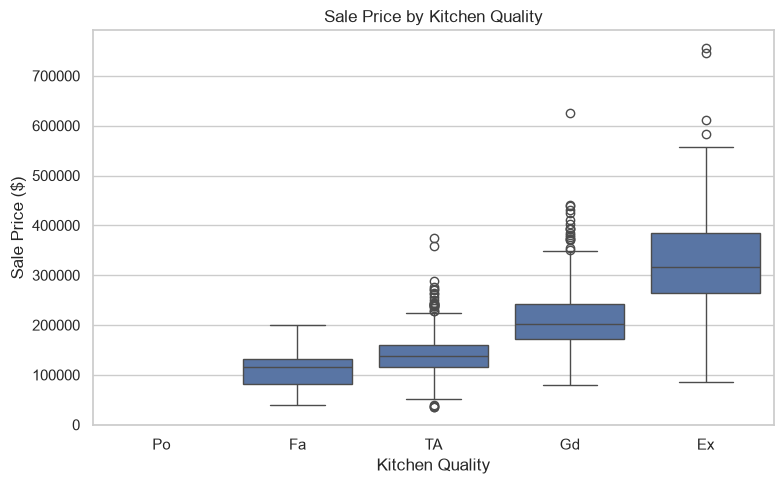

In [42]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=clean,
    x="KitchenQual",
    y="SalePrice",
    order=["Po", "Fa", "TA", "Gd", "Ex"]
)

plt.title("Sale Price by Kitchen Quality")
plt.xlabel("Kitchen Quality")
plt.ylabel("Sale Price ($)")

plt.tight_layout()
plt.show()


The analysis shows a clear relationship between kitchen quality and house selling prices. Houses with Excellent kitchen quality have the highest median selling price of $316,750, while houses with Fair kitchen quality have the lowest average selling price of approximately $105,565. The boxplot also shows several higher-priced outliers among houses with Good and Excellent kitchens. Overall, these results suggest that kitchen quality is an important feature associated with house selling prices.

#### Exterior Quality vs Selling Price

In [43]:
exterior_prices = clean.groupby("ExterQual")["SalePrice"].agg(
    ["count", "mean", "median"]
)

exterior_prices.columns = [
    "House Count",
    "Average SalePrice",
    "Median SalePrice"
]

print(exterior_prices.round(2))


           House Count  Average SalePrice  Median SalePrice
ExterQual                                                  
Ex                  52          367360.96          364606.5
Fa                  14           87985.21           82250.0
Gd                 488          231633.51          220000.0
TA                 906          144341.31          139450.0


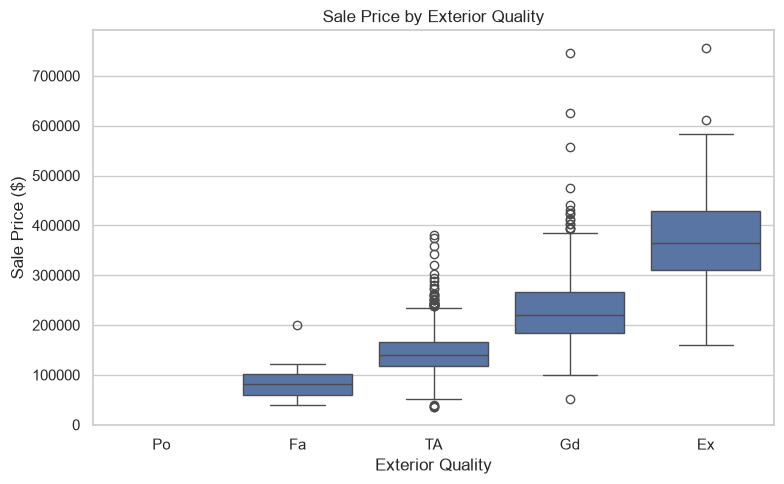

In [44]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=clean,
    x="ExterQual",
    y="SalePrice",
    order=["Po", "Fa", "TA", "Gd", "Ex"]
)

plt.title("Sale Price by Exterior Quality")
plt.xlabel("Exterior Quality")
plt.ylabel("Sale Price ($)")

plt.tight_layout()
plt.show()


The analysis shows a strong relationship between exterior quality and house selling prices. Houses with Excellent exterior quality have the highest median selling price of approximately $364,607, while houses with Fair exterior quality have the lowest median selling price of $82,250. The boxplot also shows several potential outliers, particularly among houses with Typical and Good exterior quality. Overall, these results suggest that exterior quality is an important feature associated with house selling prices.

One interesting observation is that Typical exterior quality has many outliers, so a house with Typical exterior quality might still have an excellent kitchen, a large living area, or a desirable neighborhood, driving up the price within that group.

#### Basement Quality vs Selling Price


In [47]:

bsmt_summary = clean.groupby("BsmtQual")["SalePrice"].agg(
    House_Count="count",
    Average_SalePrice="mean",
    Median_SalePrice="median"
)

bsmt_summary = bsmt_summary.sort_values(
    by="Median_SalePrice",
    ascending=False
)

print(bsmt_summary.round(2))


          House_Count  Average_SalePrice  Median_SalePrice
BsmtQual                                                  
Ex                121          327041.04          318000.0
Gd                618          202688.48          192070.0
TA                649          140759.82          135500.0
Fa                 35          115692.03          112000.0
None               37          105652.89          101800.0


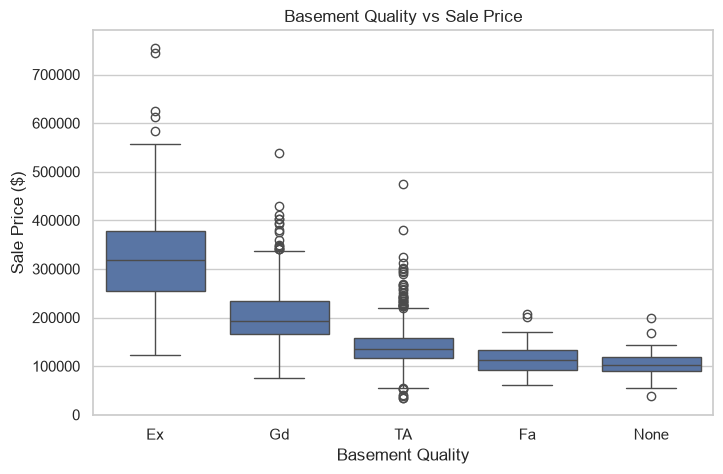

In [48]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=clean,
    x="BsmtQual",
    y="SalePrice",
    order=["Ex", "Gd", "TA", "Fa", "None"]
)

plt.title("Basement Quality vs Sale Price")
plt.xlabel("Basement Quality")
plt.ylabel("Sale Price ($)")

plt.show()


Interpretation

The analysis shows a positive relationship between basement quality and house sale price. Houses with excellent basement quality have the highest median sale price at $318,000, while houses without basements have the lowest median at $101,800.

The boxplot shows a noticeable decrease in sale prices as basement quality declines. The difference between excellent and good basement quality is particularly significant. Typical-quality basements also show the largest number of outliers.

Overall, the results suggest that basement quality is an important feature associated with house sale price. However, other factors, such as overall house quality, living area, and neighborhood, may also contribute to these differences.

#### Street Conditions vs Selling Price

In [49]:
street_summary = clean.groupby("Street")["SalePrice"].agg(
    House_Count="count",
    Average_SalePrice="mean",
    Median_SalePrice="median"
)

print(street_summary.round(2))


        House_Count  Average_SalePrice  Median_SalePrice
Street                                                  
Grvl              6          130190.50          114250.0
Pave           1454          181130.54          163000.0


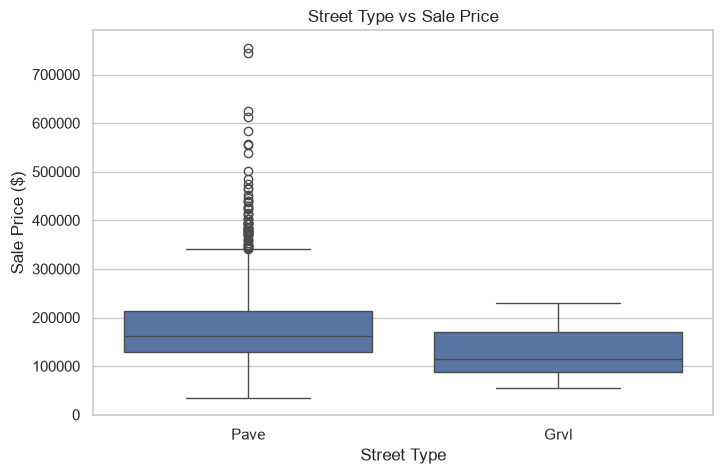

In [50]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=clean,
    x="Street",
    y="SalePrice"
)

plt.title("Street Type vs Sale Price")
plt.xlabel("Street Type")
plt.ylabel("Sale Price ($)")

plt.show()


Interpretation

The analysis shows that houses with paved streets have a higher median sale price of $163,000 compared with $114,250 for houses with gravel streets.

The boxplot shows several outliers among paved-street properties, while gravel-street properties have no visible outliers. However, this difference is likely influenced by the large imbalance in sample sizes, with 1,454 paved-street houses and only 6 gravel-street houses.

Overall, although paved streets are associated with higher sale prices in this dataset, there is insufficient evidence to conclude that street type itself has a significant influence on house sale price.

#### Month Sold vs Selling Price

In [51]:
month_summary = clean.groupby("MoSold")["SalePrice"].agg(
    House_Count="count",
    Average_SalePrice="mean",
    Median_SalePrice="median"
)

print(month_summary.round(2))


        House_Count  Average_SalePrice  Median_SalePrice
MoSold                                                  
1                58          183256.26          151650.0
2                52          177882.00          173250.0
3               106          183253.92          165250.0
4               141          171503.26          147000.0
5               204          172307.27          154000.0
6               253          177395.74          163000.0
7               234          186331.19          165195.0
8               122          184651.83          174450.0
9                63          195683.21          185900.0
10               89          179563.98          159000.0
11               79          192210.91          173000.0
12               59          186518.97          178000.0


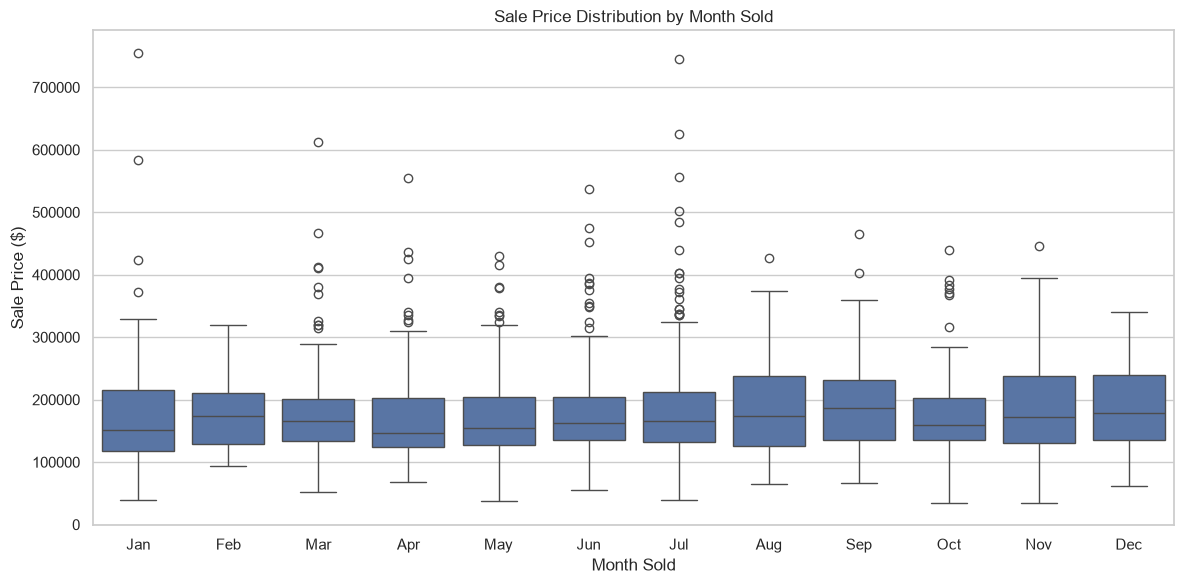

In [52]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=clean,
    x="MoSold",
    y="SalePrice",
    order=range(1, 13)
)

plt.title("Sale Price Distribution by Month Sold")
plt.xlabel("Month Sold")
plt.ylabel("Sale Price ($)")
plt.xticks(
    ticks=range(12),
    labels=["Jan", "Feb", "Mar", "Apr", "May", "Jun",
            "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.tight_layout()
plt.show()


The boxplot shows that some months have more higher-priced outliers than others. This suggests that houses sold during certain months can reach higher selling prices. However, this does not necessarily mean that the month of sale directly influences the price. Other factors, such as house quality, size, and neighborhood, may explain these higher selling prices. Therefore, the month of sale may have some influence, but it does not appear to be one of the strongest indicators of a higher sale price.

## Conclusion